[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/timecorr/blob/master/docs/tutorial/trajectories.ipynb)

# Trajectories of features at orders 1 to 4

This tutorial computes features of orders 1 to 4 with `tc.features` on three real datasets from different domains, reduces each order to three dimensions, and animates the result as a trajectory with [hypertools](https://hypertools.readthedocs.io/). You will see how to compare the shape of a dataset's trajectory across orders.

**Data.**

- *Brain activity during story listening*: the HTFA node weights of 36 people listening to a story (Simony et al., 2016, [doi:10.1038/ncomms12141](https://doi.org/10.1038/ncomms12141)), as analyzed by Owen, Chang & Manning (2021, [doi:10.1038/s41467-021-25876-x](https://doi.org/10.1038/s41467-021-25876-x)). The [HTFA tutorial](htfa_network_animations.ipynb) describes the data; the archive is 460 MB.
- *Stock market*: the daily log returns of the 49 US industry portfolios of the [Kenneth R. French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html), 2005 to 2024, as in the [stock-market tutorial](stocks.ipynb).
- *Human movement*: trial 2 of subject 86 of the [CMU Graphics Lab Motion Capture Database](http://mocap.cs.cmu.edu/) ("walk, squats, run, stretch, jumps, punches, and drinking", [trial list](http://mocap.cs.cmu.edu/search.php?subjectnumber=86)): the joint angles of one person, recorded at 120 frames per second. The data used here were obtained from mocap.cs.cmu.edu; the database was created with funding from NSF EIA-0196217.

Downloads are cached in the folder set by the `TIMECORR_DATA` environment variable (default `~/timecorr_data`). Most of the run time goes to rendering the videos; the last cell prints it.

In [1]:
# On Google Colab, install timecorr (this cell does nothing elsewhere): release 0.3.1 or
# later from PyPI, or, when pip cannot install that (it then prints an error first),
# the master branch on GitHub.
# bottleneck>=1.5: pandas 3, which the tutorial extras install, warns about the older
# bottleneck that Colab has.
import sys

if 'google.colab' in sys.modules:
    !pip install -q "timecorr[tutorials]>=0.3.1" "bottleneck>=1.5" || pip install -q "timecorr[tutorials] @ git+https://github.com/ContextLab/timecorr.git@master" "bottleneck>=1.5"

In [2]:
import time
import warnings

import hypertools as hyp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

import timecorr as tc

%matplotlib inline
NOTEBOOK_START = time.time()
print('timecorr', tc.__version__, '| hypertools', hyp.__version__)

timecorr 0.3.1 | hypertools 1.2.0


## 1. Loading the three datasets

**Story listening.** As in the HTFA tutorial: the node weights of the intact condition, the nodes whose weights are never constant, and 100 of them spread over the brain by farthest-point sampling. The result is one matrix (timepoints by nodes) per participant.

In [3]:
story = tc.datasets.story_listening(n_nodes=100)     # the data of the HTFA tutorial
print(f'story listening: {len(story)} participants, each {story[0].shape[0]} timepoints by {story[0].shape[1]} nodes')

story listening: 36 participants, each 300 timepoints by 100 nodes


**Stock market.** As in the stock-market tutorial: the value-weighted daily returns of the 49 industries, 2005 to 2024, as log returns.

In [4]:
returns = tc.datasets.industry_returns('2005-01-01', '2024-12-31')
stock_dates, stocks = returns.index, returns.values
print(f'stock market: {stocks.shape[0]} trading days by {stocks.shape[1]} industries')

stock market: 5033 trading days by 49 industries


**Human movement.** The motion file (AMC format) lists, for every frame, the angles of each joint in degrees. The cell keeps the joint angles (not the position and orientation of the body as a whole), drops the angles that never change, removes the 360-degree jumps of angles that wrap around, and averages blocks of 10 frames (12 samples per second).

In [5]:
amc = tc.datasets.fetch('http://mocap.cs.cmu.edu/subjects/86/86_02.amc', 'cmu_mocap/86_02.amc',
                        sha256='c89f384eddeee3bf1baf7311058d36b10fcdd70c900ba8d30197a391e61cd990')

frames, current = [], None
for line in amc.read_text().splitlines():
    if line.startswith(('#', ':')):
        continue
    fields = line.split()
    if len(fields) == 1 and fields[0].isdigit():         # a frame number starts a new frame
        current = {}
        frames.append(current)
    elif current is not None:
        current[fields[0]] = [float(v) for v in fields[1:]]
channels = [(joint, i) for joint, values in frames[0].items() if joint != 'root' for i in range(len(values))]
angles = np.array([[f[joint][i] for joint, i in channels] for f in frames])
angles = angles[:, angles.std(axis=0) > 1e-3]          # angles that change
angles = np.unwrap(angles, period=360, axis=0)
n = len(angles) // 10 * 10
movement = angles[:n].reshape(-1, 10, angles.shape[1]).mean(axis=1)
MOVEMENT_RATE = 12                                      # samples per second
print(f'human movement: {len(frames)} frames ({len(frames) / 120:.1f} s) -> '
      f'{movement.shape[0]} samples by {movement.shape[1]} joint angles')

human movement: 10617 frames (88.5 s) -> 1061 samples by 50 joint angles


## 2. Features of orders 1 to 4

For each dataset, `tc.features(data, order=4, return_info=True)` with the defaults. For the story-listening data, the features are computed per participant and then averaged over participants. The cell prints the number of columns of each order's features and the warnings that `tc.features` issues.

The defaults choose each kernel's width from the data, and `return_info` records it. Near the ends of a recording the kernels are cut off, and the features there are far from those in the middle, which would squeeze the rest of a trajectory into a corner of the plot. So the cell leaves out the first and last `edge` timepoints, twice the largest kernel standard deviation (printed).

A warning about a constant `WeightedStrength` column refers to the line `constant:` below it, which names the column. A magnitude column with value 0 belongs to a feature whose pair weights are all in the low group that centering subtracts (`a_ij = max(w_ij - m, 0)` in `tc.WeightedStrength`).

In [6]:
DATASETS = {'Story listening': story, 'Stock market': stocks, 'Human movement': movement}
features, edges = {}, {}
for name, data in DATASETS.items():
    print(f'{name}: computing features ({time.time() - NOTEBOOK_START:.0f} s after the start)', flush=True)
    start = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', UserWarning)  # timecorr warns with UserWarning
        X, info = tc.features(data, order=4, return_info=True)
    caught = [w for w in caught if issubclass(w.category, UserWarning)]  # timecorr's warnings only
    # the columns that are constant over time, from the record of each analysis step
    # (index [participant] for lists; magnitude columns come first)
    constant = []
    for step in (s for s in info if s['path'] == 'analysis'):
        k, listed = step['order'], isinstance(X[step['order']], list)
        for p, columns in enumerate(step['constant_columns'] if listed else [step['constant_columns']]):
            x, where = (X[k][p], f'X[{k}][{p}]') if listed else (X[k], f'X[{k}]')
            for c in columns:
                kind = 'magnitude' if k >= 2 and c < x.shape[1] // 2 else 'column'
                constant.append(f'  constant: {where}[:, {c}] ({kind}), value {x[0, c]:.3g}')
    if isinstance(data, list):
        X = [np.mean(x, axis=0) for x in X]
    # kernel standard deviations in timepoints (rows of each order's input times timepoints per row)
    widest = max(step['kernel_sd'] * step.get('sampling', 1) for step in info)
    edges[name] = edge = int(np.ceil(2 * widest))
    features[name] = [x[edge:len(x) - edge] for x in X]
    widths = ', '.join(f'X[{k}]: {X[k].shape[1]}' for k in range(1, 5))
    print(f'{name}: {time.time() - start:.0f} s; columns {widths}; '
          f'largest kernel sd {widest:.0f} timepoints, edge {edge}')
    for message in sorted({str(w.message) for w in caught}):
        print(f'  warning ({sum(str(w.message) == message for w in caught)}x): {message}')
    for line in constant:
        print(line)

Story listening: computing features (1 s after the start)


Story listening: 34 s; columns X[1]: 100, X[2]: 200, X[3]: 8, X[4]: 8; largest kernel sd 10 timepoints, edge 20
  warning (1x): WeightedStrength: 1 output column is constant over time (zero variance, or a range within round-off of 0, set to the column's mean), for example because every weight is 0; returned as computed otherwise.
  constant: X[4][31][:, 3] (magnitude), value 0
Stock market: computing features (35 s after the start)


Stock market: 2 s; columns X[1]: 49, X[2]: 18, X[3]: 18, X[4]: 18; largest kernel sd 50 timepoints, edge 101
Human movement: computing features (37 s after the start)


Human movement: 1 s; columns X[1]: 50, X[2]: 10, X[3]: 10, X[4]: 10; largest kernel sd 11 timepoints, edge 22
  warning (1x): Automatic feeding reducer at order 2: the shift null found no structure (no eigenvalue above null_threshold=0.1865); this order uses WeightedStrength on its 5 input features.
  warning (1x): Automatic feeding reducer at order 3: the shift null found no structure (no eigenvalue above null_threshold=0.1383); this order uses WeightedStrength on its 5 input features.


## 3. The trajectories

`cube_coordinates` reduces one order's features to three dimensions with `hyp.reduce` (hypertools' default, incremental PCA, fit separately for each order) and rescales each of the three components to its own range. Without that step the cube would be scaled by the first component alone, and the weaker components would look flat.

`hyp.plot(..., panels=...)` then draws one cube per trajectory in a single figure. Each axis is scaled separately, so compare the paths, not distances along different axes. `antialias=False` draws straight segments between the samples, so every vertex of a line is a sample. Rows are datasets, columns are orders.

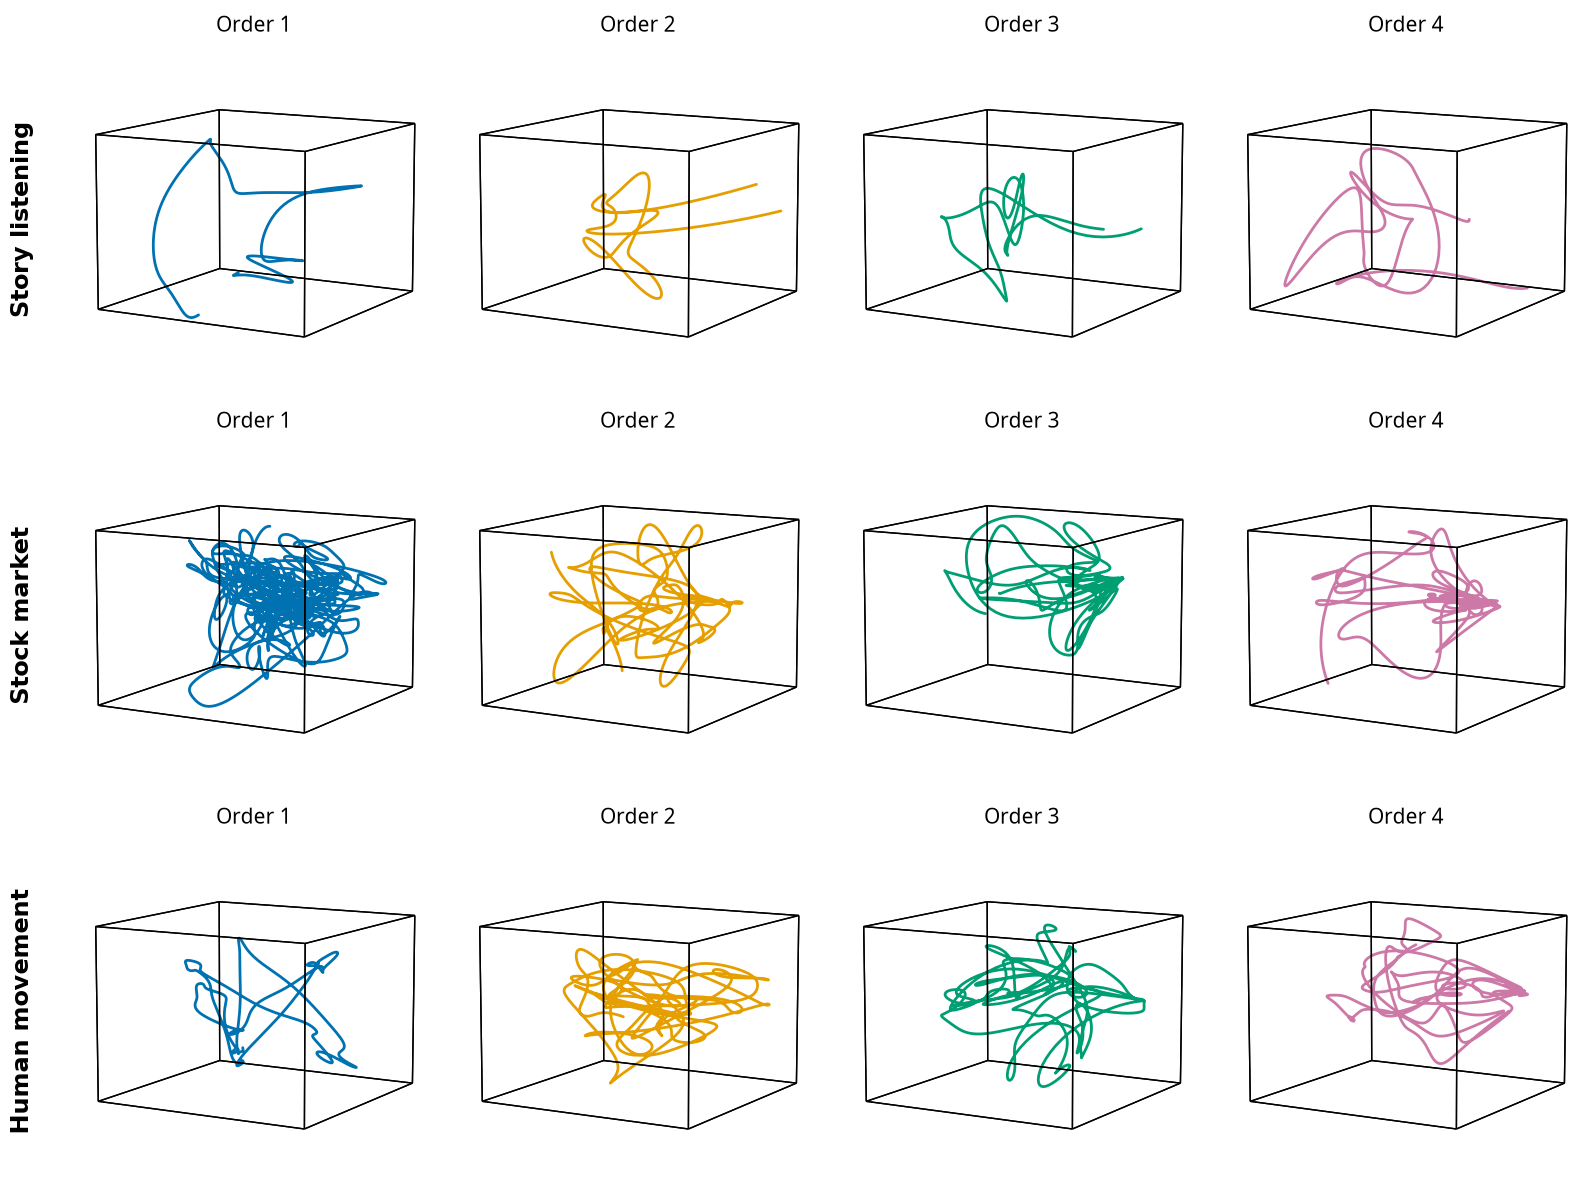

In [7]:
COLORS = ['#0072B2', '#E69F00', '#009E73', '#CC79A7']          # one color per order
ORDER_TITLES = [f'Order {k}' for k in range(1, 5)]


def cube_coordinates(x):
    """Three hypertools components of x, each rescaled to its own range."""
    y = np.asarray(hyp.reduce(x, ndims=3))
    return (y - y.min(axis=0)) / np.ptp(y, axis=0)


coordinates = {name: [cube_coordinates(X[k]) for k in range(1, 5)] for name, X in features.items()}

fig = hyp.plot([c for name in coordinates for c in coordinates[name]], panels=(3, 4), reduce=None,
               title=ORDER_TITLES * 3, title_kwargs={'fontsize': 15}, color=COLORS * 3, linewidth=2,
               antialias=False, size=(16, 12), show=False, backend='matplotlib')
fig.subplots_adjust(left=0.04, right=1, bottom=0, top=0.96, wspace=0, hspace=0.1)
for row, name in enumerate(coordinates):
    box = fig.axes[4 * row].get_position()
    fig.text(0.015, (box.y0 + box.y1) / 2, name, rotation=90, ha='center', va='center',
             fontsize=17, weight='bold')
display(fig)
plt.close(fig)

## 4. Animations

One video per dataset, with the four orders side by side. Each frame shows one sample: the line up to that sample, faint, with the last `TAIL` samples solid. Nothing is drawn between samples, and the frames follow the samples at 30 frames per second; for long recordings, only every `step`-th sample gets a frame (the step is given for each video). The camera turns slowly.

`hyp.plot(..., panels=..., animate=True)` draws the frames: `chemtrails=True` keeps the faint line behind the solid tail, and `caption=` writes one line per frame. The notebook then enlarges that caption, adds a title and saves the video (H.264, 1920 x 600). In the documentation the videos are linked files; elsewhere (for example on Colab) they are saved in `tutorial_media/` and shown inline.

In [8]:
FPS = 30
TAIL = 30                                                    # samples drawn solid
DEGREES_PER_FRAME = 0.25                                     # camera turn


def render(name, step, captions):
    coords = coordinates[name]
    n_frames = (len(coords[0]) - 1) // step + 1             # every step-th sample, ending on the last
    start = time.time()
    animation = hyp.plot(coords, panels=(1, 4), reduce=None, animate=True, chemtrails=True,
                         duration=n_frames / FPS, frame_rate=FPS, tail_duration=TAIL / (FPS * step),
                         rotations=DEGREES_PER_FRAME * n_frames / 360,
                         caption=lambda frame: captions(frame.revealed_counts[0] - 1),
                         title=ORDER_TITLES, title_kwargs={'fontsize': 24}, color=COLORS, linewidth=2.5,
                         antialias=False, size=(19.2, 6.0), show=False, backend='matplotlib')
    # hypertools draws the caption small and under the cubes: move it to the top right, and add a title
    fig = animation.figure
    caption = fig.findobj(lambda artist: artist.get_gid() == 'hypertools-caption')[0]
    caption.set(position=(0.985, 0.97), ha='right', va='top', fontsize=26, color='#444444')
    fig.suptitle(f'{name}: features of orders 1 to 4', x=0.015, y=0.97, ha='left', va='top',
                 fontsize=30, weight='bold')
    fig.subplots_adjust(top=0.8, bottom=0)                  # room for them above the cubes
    # tc.media_dir(): docs/_static/tutorial_media inside the documentation sources (docs/tutorial), where
    # tc.show_video links the video; ./tutorial_media anywhere else (for example on Colab), where it embeds it
    path = tc.media_dir() / f'trajectories_{name.replace(" ", "_").lower()}.mp4'
    animation.save(path)
    plt.close(fig)
    print(f'{n_frames} samples (every {step}) -> {n_frames} frames ({n_frames / FPS:.1f} s) '
          f'in {time.time() - start:.0f} s; {path.name}: {path.stat().st_size / 1e6:.1f} MB')
    tc.show_video(path)

### Story listening

Every timepoint gets a frame (step 1).

In [9]:
T, edge = len(features['Story listening'][1]), edges['Story listening']
render('Story listening', 1, lambda s: f'timepoint {s + edge + 1} of {T + 2 * edge}')

260 samples (every 1) -> 260 frames (8.7 s) in 22 s; trajectories_story_listening.mp4: 0.7 MB


Order 1 follows a smooth, open path with a few wide turns. Orders 2 to 4 each make several loops and cross themselves.

### Stock market

Every 4th trading day gets a frame (step 4), as in the network video of the [stock-market tutorial](stocks.ipynb).

In [10]:
days = stock_dates[edges['Stock market']:len(stock_dates) - edges['Stock market']]
render('Stock market', 4, lambda s: days[s].strftime('%d %B %Y'))

1208 samples (every 4) -> 1208 frames (40.3 s) in 113 s; trajectories_stock_market.mp4: 4.1 MB


Order 1 forms a dense tangle: the trajectory keeps returning to states it has visited before instead of drifting away. Orders 2 to 4 are smoother, with fewer and larger loops, and at orders 3 and 4 most loops start and end in one region.

### Human movement

Every sample gets a frame (step 1), so the video plays at 2.5 times the speed of the movement (12 samples per second of movement, 30 frames per second of video).

In [11]:
T, edge = len(features['Human movement'][1]), edges['Human movement']
render('Human movement', 1, lambda s: f'{(s + edge) / MOVEMENT_RATE:.1f} s of {(T + 2 * edge) / MOVEMENT_RATE:.1f} s')

1017 samples (every 1) -> 1017 frames (33.9 s) in 81 s; trajectories_human_movement.mp4: 3.2 MB


Order 1 moves along a few long, straight strokes that cross; orders 2 to 4 form tangles of loops.

## Summary

- `tc.features` gave features of orders 1 to 4 for brain activity, stock returns and body movement.
- hypertools reduced each order to three dimensions and drew it as a trajectory, still (section 3) and one sample per frame (section 4).

The picture on this tutorial's card in the gallery: the order-1 trajectory of the human-movement data.

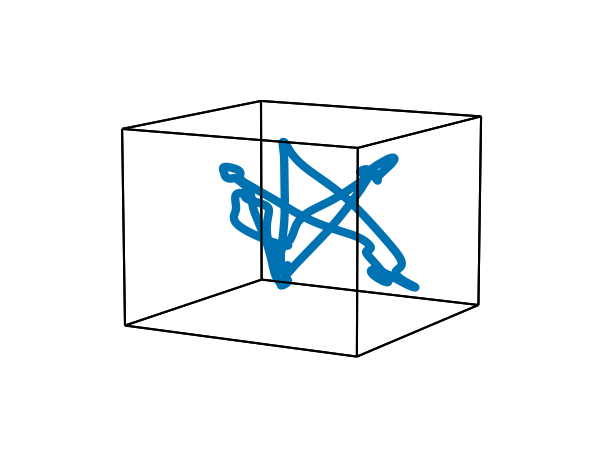

In [12]:
# the saved picture is the whole 4:3 figure (the default crops it to its content)
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}
fig = hyp.plot(coordinates['Human movement'][0], reduce=None, color=COLORS[0], linewidth=4,
               antialias=False, size=(4, 3), show=False, backend='matplotlib')
fig.set_facecolor('white')
fig.set_dpi(150)
display(fig)
plt.close(fig)

In [13]:
print(f'notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} min')

notebook run time: 4.3 min
